# Segment Anything 3 (SAM 3)

[SAM 3](https://ai.meta.com/research/publications/sam-3-segment-anything-with-concepts/) (Meta, November 2025) is the
third generation of Meta's *Segment Anything* models:

| model | year | prompt | output |
|---|---|---|---|
| SAM | 2023 | points, boxes on an image | a mask for the **one object** you pointed at |
| SAM 2 | 2024 | points, boxes on a video frame | that object's mask, **tracked** through the video |
| SAM 3 | 2025 | a **concept**: a short noun phrase ("goat", "yellow school bus") or example boxes | masks of **all instances** of the concept, in images and videos |

SAM 3 calls this *Promptable Concept Segmentation*: you name what you want, and it returns every matching object with a
box, a mask, and a confidence score. It can still do SAM 2-style clicks and tracking, too.

This notebook shows how to use it with the `transformers` library. It needs a **GPU instance** (`ml.g4dn.4xlarge`):
the model has 840 M parameters (3.4 GB) and works on 1008 × 1008 images.

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import requests
import s3fs
import torch
from PIL import Image
from transformers.utils import logging as transformers_logging

transformers_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()
warnings.filterwarnings("ignore", category=FutureWarning)  # deprecations inside the libraries
# The figures are mostly photos: JPEG at retina resolution keeps the notebook small (PNG would be ~10x larger).
%config InlineBackend.figure_formats = ['jpeg']
%config InlineBackend.print_figure_kwargs = {'bbox_inches': 'tight', 'dpi': 144, 'pil_kwargs': {'quality': 85}}

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, torch.cuda.get_device_name() if device == "cuda" else "(slow: use a GPU instance)")

device: cuda NVIDIA A100-SXM4-40GB


## Loading the model

The weights on Hugging Face (`facebook/sam3`) require accepting Meta's license with a Hugging Face account. For this
course, a copy with its license (the *SAM License*, which allows redistribution with the license attached) is in the
course bucket. The first run downloads it (3.4 GB) to `sam3_model/` next to this notebook; later runs load it from there.

In [2]:
MODEL_S3 = "danylo-ucla/models/facebook/sam3"
MODEL_DIR = Path("sam3_model")

if not (MODEL_DIR / "model.safetensors").exists():
    s3fs.S3FileSystem().get(f"{MODEL_S3}/", str(MODEL_DIR), recursive=True)
print(sorted(p.name for p in MODEL_DIR.iterdir()))

['LICENSE', 'README.md', 'config.json', 'merges.txt', 'model.safetensors', 'processor_config.json', 'special_tokens_map.json', 'tokenizer.json', 'tokenizer_config.json', 'vocab.json']


In [3]:
from transformers import Sam3Model, Sam3Processor

model = Sam3Model.from_pretrained(MODEL_DIR).to(device).eval()
processor = Sam3Processor.from_pretrained(MODEL_DIR)

print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.0f} M parameters")
{name: f"{sum(p.numel() for p in m.parameters()) / 1e6:.0f} M" for name, m in model.named_children()}

840 M parameters


{'vision_encoder': '454 M',
 'text_encoder': '353 M',
 'text_projection': '0 M',
 'geometry_encoder': '8 M',
 'detr_encoder': '9 M',
 'detr_decoder': '12 M',
 'mask_decoder': '2 M',
 'dot_product_scoring': '1 M'}

The two big parts are a **vision encoder** (a ViT for the image) and a **text encoder** (for the prompt). A small
DETR-style **detector** (`detr_encoder`, `detr_decoder`) then matches the image against the prompt, and a
**mask decoder** draws a mask for each detected object.

### Images and a plotting helper

The example images are from the COCO validation set. `show` draws each mask in one color with a white outline, and
optionally the boxes and scores.

In [4]:
def load_coco(image_id: int) -> Image.Image:
    url = f"https://s3.us-east-1.amazonaws.com/images.cocodataset.org/val2017/{image_id:012d}.jpg"
    return Image.open(requests.get(url, stream=True).raw).convert("RGB")


COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]  # one per prompt or object


def show(ax, image, masks, boxes=None, scores=None, color=COLORS[0], title=""):
    """Image with masks (N, H, W) overlaid; boxes (N, 4) in xyxy pixels and scores (N,) are optional."""
    ax.imshow(image)
    masks = np.asarray(masks, dtype=bool)
    if len(masks):
        overlay = np.zeros((*masks.shape[1:], 4))
        overlay[masks.any(axis=0)] = (*plt.matplotlib.colors.to_rgb(color), 0.5)
        ax.imshow(overlay)
        for mask in masks:
            ax.contour(mask, levels=[0.5], colors="white", linewidths=0.8)
    for i, box in enumerate([] if boxes is None else np.asarray(boxes)):
        x0, y0, x1, y1 = box
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor=color, lw=1.5))
        if scores is not None:
            ax.text(x0, y0 - 2, f"{float(scores[i]):.2f}", color="white", fontsize=7,
                    bbox=dict(facecolor=color, edgecolor="none", pad=1))
    ax.set_title(title, fontsize=10)
    ax.axis("off")

## 1. Text prompts: segment every instance of a concept

The processor resizes the image to 1008 × 1008, normalizes it, and tokenizes the text prompt. The model returns raw
predictions for **200 candidate objects** (*queries*), most of which match nothing.

In [5]:
cats = load_coco(39769)
inputs = processor(images=cats, text="cat", return_tensors="pt").to(device)
print({name: tuple(value.shape) for name, value in inputs.items()})

with torch.no_grad():
    outputs = model(**inputs)
{name: tuple(value.shape) for name, value in outputs.items()}

{'pixel_values': (1, 3, 1008, 1008), 'original_sizes': (1, 2), 'input_ids': (1, 32), 'attention_mask': (1, 32)}


{'pred_masks': (1, 200, 288, 288),
 'pred_boxes': (1, 200, 4),
 'pred_logits': (1, 200),
 'presence_logits': (1, 1),
 'semantic_seg': (1, 1, 288, 288),
 'decoder_reference_boxes': (6, 1, 200, 4)}

The outputs, for each of the 200 queries:

- `pred_logits`: does this query match the prompt?
- `pred_boxes`: a box (x0, y0, x1, y1), as fractions of the image size;
- `pred_masks`: a 288 × 288 mask (logits);
- and once per image, `presence_logits`: is the concept in the image *at all*?

The score of each query is $\sigma(\text{logit}) \cdot \sigma(\text{presence logit})$. Separating "is there a cat?"
from "which of these candidates are cats?" makes the model much better at returning *nothing* for absent concepts.
`post_process_instance_segmentation` computes the scores, keeps the queries above `threshold`, scales the boxes to
pixels, resizes the masks to the original image and binarizes them at `mask_threshold`:

{'scores': (2,), 'boxes': (2, 4), 'masks': (2, 480, 640)} scores: [0.9700000286102295, 0.9700000286102295]


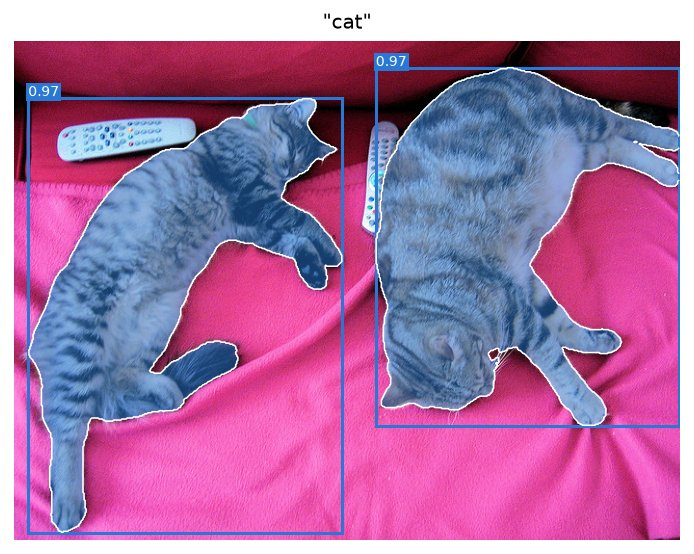

In [6]:
results = processor.post_process_instance_segmentation(
    outputs, threshold=0.5, mask_threshold=0.5, target_sizes=inputs["original_sizes"].tolist()
)[0]
print({name: tuple(value.shape) for name, value in results.items()}, "scores:", results["scores"].round(decimals=2).tolist())

fig, ax = plt.subplots(figsize=(6, 4.5))
show(ax, cats, results["masks"].cpu(), results["boxes"].cpu(), results["scores"].cpu(), title='"cat"')
plt.show()

Let's wrap these steps in a function, and try a few images with many instances:

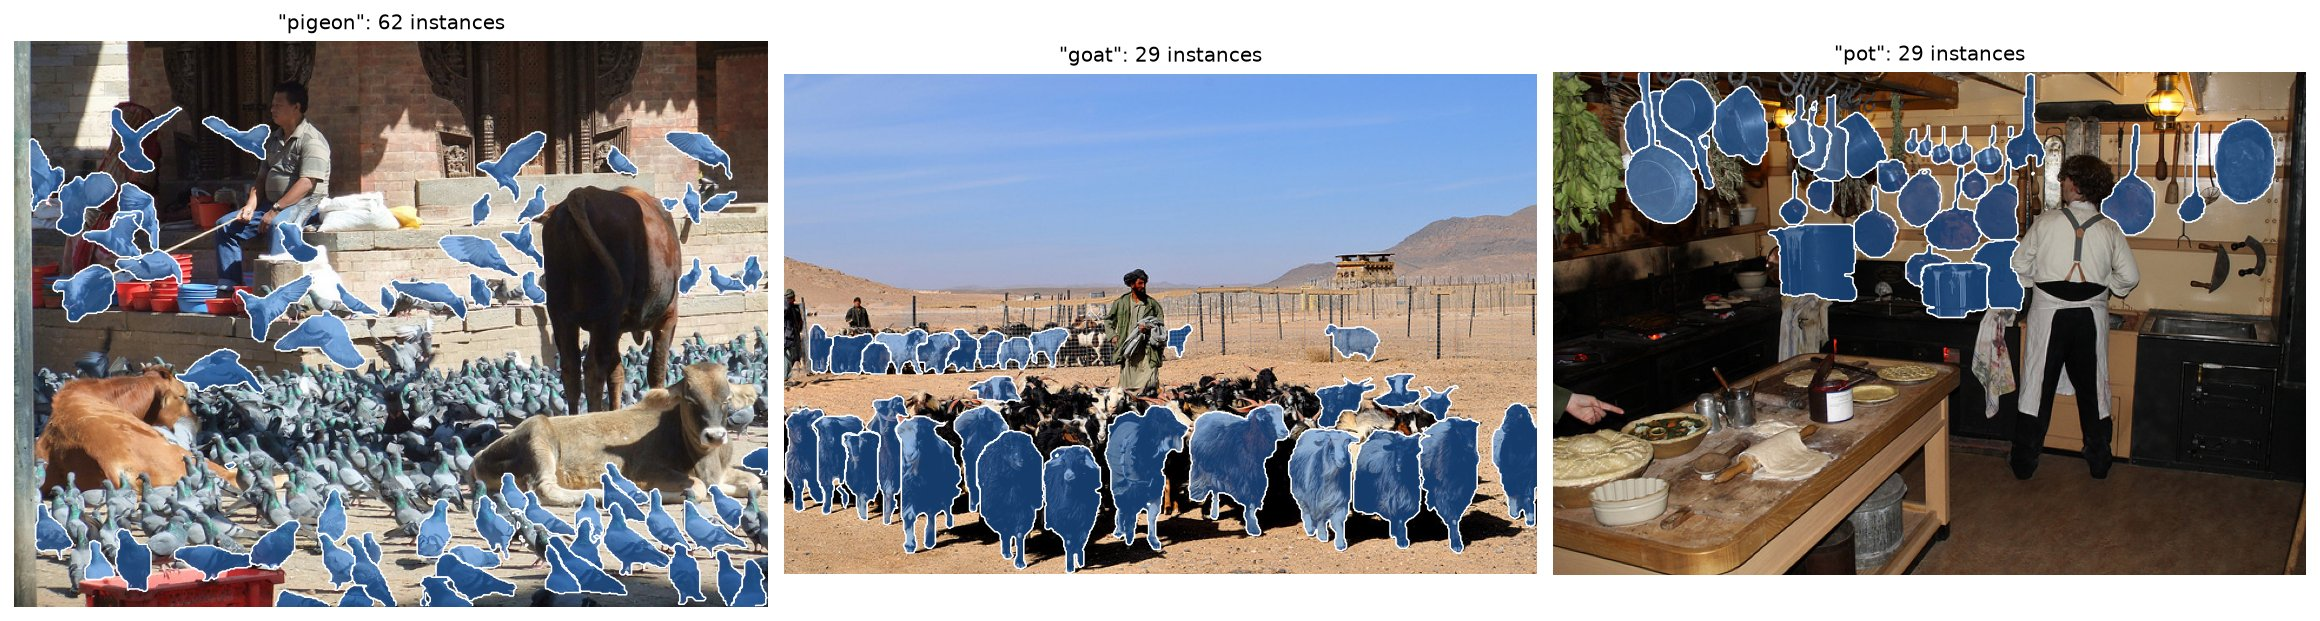

In [7]:
def segment(image, text, threshold=0.5):
    inputs = processor(images=image, text=text, return_tensors="pt").to(device)
    with torch.no_grad():
        outputs = model(**inputs)
    results = processor.post_process_instance_segmentation(
        outputs, threshold=threshold, target_sizes=inputs["original_sizes"].tolist()
    )[0]
    return {name: value.cpu() for name, value in results.items()}


examples = [(load_coco(60823), "pigeon"), (load_coco(181666), "goat"), (load_coco(397133), "pot")]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), layout="constrained")
for ax, (image, text) in zip(axes, examples):
    results = segment(image, text)
    show(ax, image, results["masks"], title=f'"{text}": {len(results["masks"])} instances')
plt.show()

### The threshold

The scores of all 200 queries for "pigeon": the threshold decides how many of them count as detections. Lower
thresholds find more of the small or partly hidden birds, and more false detections.

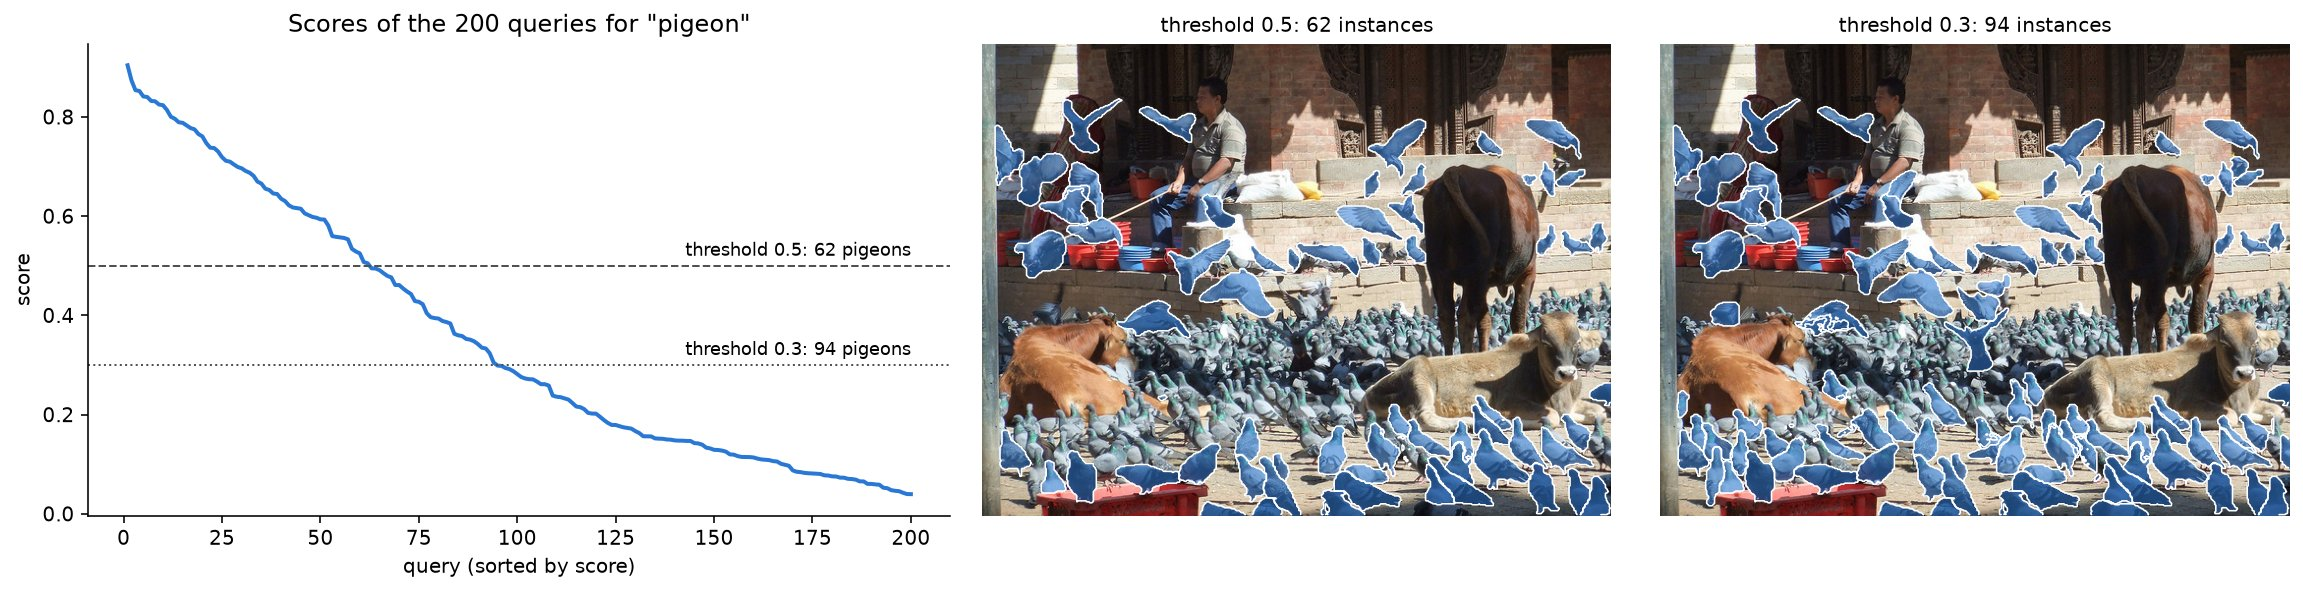

In [8]:
pigeons = examples[0][0]
inputs = processor(images=pigeons, text="pigeon", return_tensors="pt").to(device)
with torch.no_grad():
    outputs = model(**inputs)
scores = (outputs.pred_logits.sigmoid() * outputs.presence_logits.sigmoid())[0].sort(descending=True).values.cpu()

fig, axes = plt.subplots(1, 3, figsize=(16, 4), layout="constrained", gridspec_kw={"width_ratios": [1.3, 1, 1]})
axes[0].plot(range(1, 201), scores, color=COLORS[0], lw=2)
for threshold, style in [(0.5, "--"), (0.3, ":")]:
    axes[0].axhline(threshold, color="#52514e", ls=style, lw=1)
    axes[0].text(200, threshold + 0.02, f"threshold {threshold}: {int((scores > threshold).sum())} pigeons",
                 ha="right", fontsize=9)
axes[0].set(xlabel="query (sorted by score)", ylabel="score", title='Scores of the 200 queries for "pigeon"')
axes[0].spines[["top", "right"]].set_visible(False)
for ax, threshold in zip(axes[1:], [0.5, 0.3]):
    results = segment(pigeons, "pigeon", threshold=threshold)
    show(ax, pigeons, results["masks"], title=f"threshold {threshold}: {len(results['masks'])} instances")
plt.show()

### Absent concepts and the presence score

The presence score answers "is this concept in the image?". For concepts that aren't there, it is close to 0 and
pulls every query's score down with it:

In [9]:
for text in ["cat", "remote control", "pillow", "dog", "person"]:
    inputs = processor(images=cats, text=text, return_tensors="pt").to(device)
    with torch.no_grad():
        outputs = model(**inputs)
    presence = outputs.presence_logits.sigmoid().item()
    print(f"{text:15s} presence {presence:.3f}   instances above 0.5: {len(segment(cats, text)['masks'])}")

cat             presence 0.995   instances above 0.5: 2


remote control  presence 0.999   instances above 0.5: 2


pillow          presence 0.236   instances above 0.5: 0


dog             presence 0.002   instances above 0.5: 0


person          presence 0.005   instances above 0.5: 0


### Several prompts on one image: reuse the image embedding

The vision encoder is the expensive part, and it doesn't depend on the prompt. To try several prompts on the same image,
encode the image once with `get_vision_features`, then pass `vision_embeds` instead of `pixel_values`.

image encoded once in 0.06 s


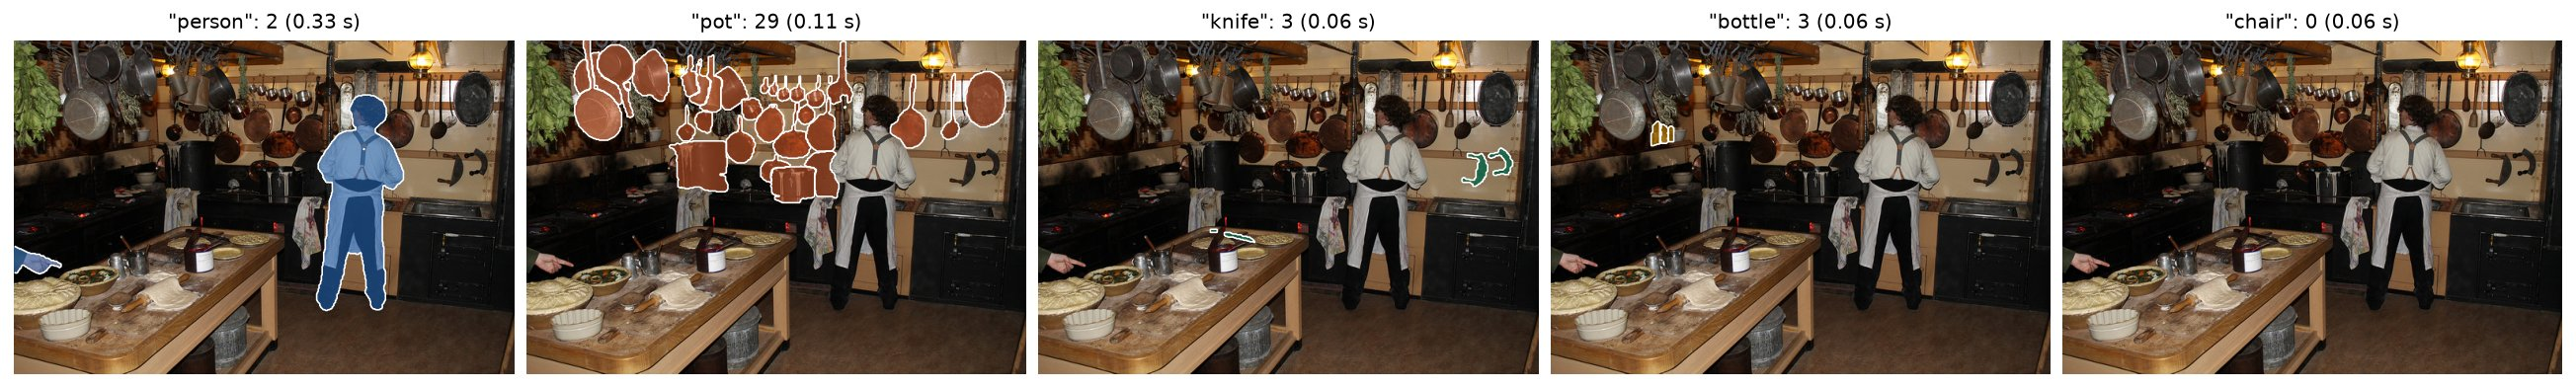

In [10]:
kitchen = examples[2][0]
prompts = ["person", "pot", "knife", "bottle", "chair"]

with torch.no_grad():
    image_inputs = processor(images=kitchen, return_tensors="pt").to(device)
    start = time.time()
    vision_embeds = model.get_vision_features(pixel_values=image_inputs["pixel_values"])
    print(f"image encoded once in {time.time() - start:.2f} s")

    fig, axes = plt.subplots(1, len(prompts), figsize=(18, 3.4), layout="constrained")
    for ax, text, color in zip(axes, prompts, COLORS):
        start = time.time()
        text_inputs = processor(text=text, return_tensors="pt").to(device)
        outputs = model(vision_embeds=vision_embeds, **text_inputs)
        results = processor.post_process_instance_segmentation(
            outputs, threshold=0.5, target_sizes=image_inputs["original_sizes"].tolist()
        )[0]
        show(ax, kitchen, results["masks"].cpu(), color=color,
             title=f'"{text}": {len(results["masks"])} ({time.time() - start:.2f} s)')
plt.show()

## 2. Visual prompts: example boxes

Instead of (or together with) text, the concept can be given by example: a box around **one** object, and the model
finds **all** objects like it. Boxes are in pixels, `[x0, y0, x1, y1]`, with a label for each box:
`1` = "like this", `0` = "not like this". The nesting is `[image][box]`.

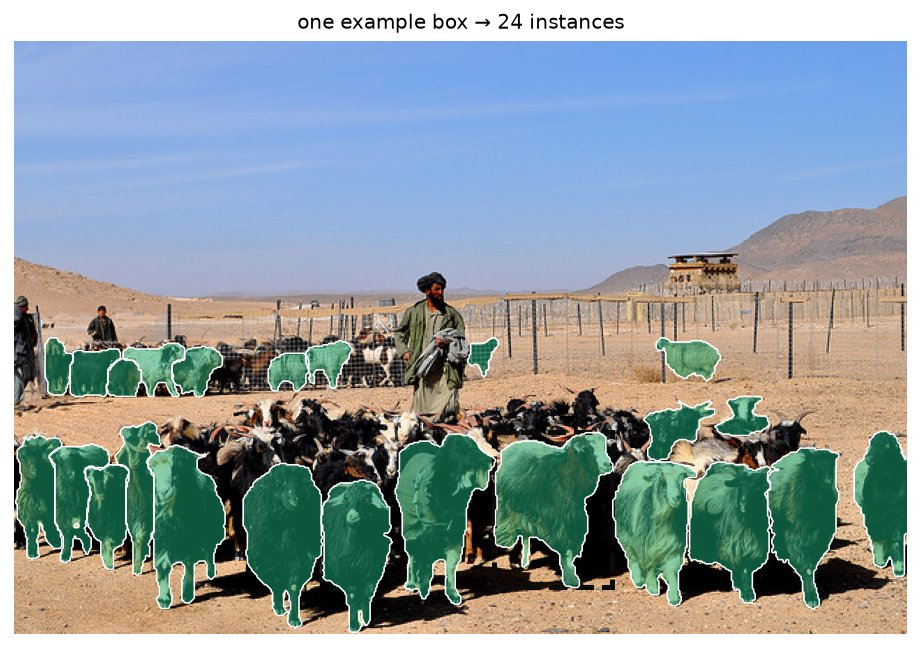

In [11]:
goats = examples[1][0]
example_box = [343, 280, 428, 391]  # one goat

inputs = processor(images=goats, input_boxes=[[example_box]], input_boxes_labels=[[1]], return_tensors="pt").to(device)
with torch.no_grad():
    outputs = model(**inputs)
results = processor.post_process_instance_segmentation(
    outputs, threshold=0.5, target_sizes=inputs["original_sizes"].tolist()
)[0]

fig, ax = plt.subplots(figsize=(8, 5.5))
show(ax, goats, results["masks"].cpu(), color=COLORS[2], title=f"one example box → {len(results['masks'])} instances")
x0, y0, x1, y1 = example_box
ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="#0b0b0b", lw=2.5, ls="--"))
plt.show()

A **negative** box (label `0`) together with a text prompt removes a kind of object from the results. In the kitchen,
"person" finds the cook and a hand at the left edge; a negative box on the cook leaves only the hand:

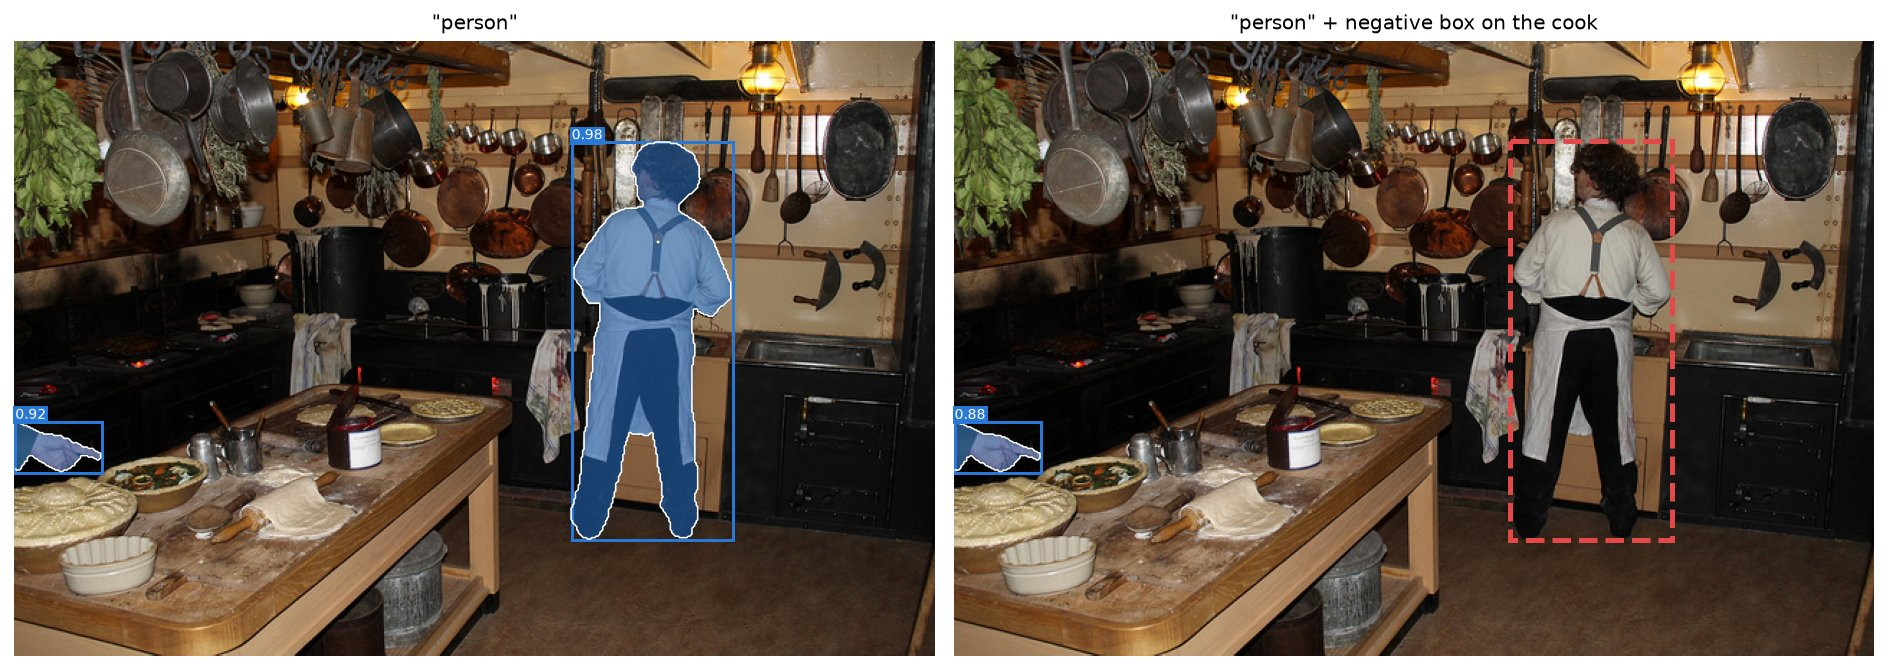

In [12]:
cook_box = [386, 69, 499, 346]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
for ax, (boxes, labels, title) in zip(axes, [(None, None, '"person"'),
                                             ([[cook_box]], [[0]], '"person" + negative box on the cook')]):
    inputs = processor(images=kitchen, text="person", input_boxes=boxes, input_boxes_labels=labels,
                       return_tensors="pt").to(device)
    with torch.no_grad():
        outputs = model(**inputs)
    results = processor.post_process_instance_segmentation(
        outputs, threshold=0.5, target_sizes=inputs["original_sizes"].tolist()
    )[0]
    show(ax, kitchen, results["masks"].cpu(), results["boxes"].cpu(), results["scores"].cpu(), title=title)
    if boxes:
        x0, y0, x1, y1 = cook_box
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="#e34948", lw=2.5, ls="--"))
plt.show()

## 3. Batches

Several images, each with its own prompt, in one forward pass. Images are resized to the same 1008 × 1008, so they
can be batched; `original_sizes` remembers each image's size for post-processing.

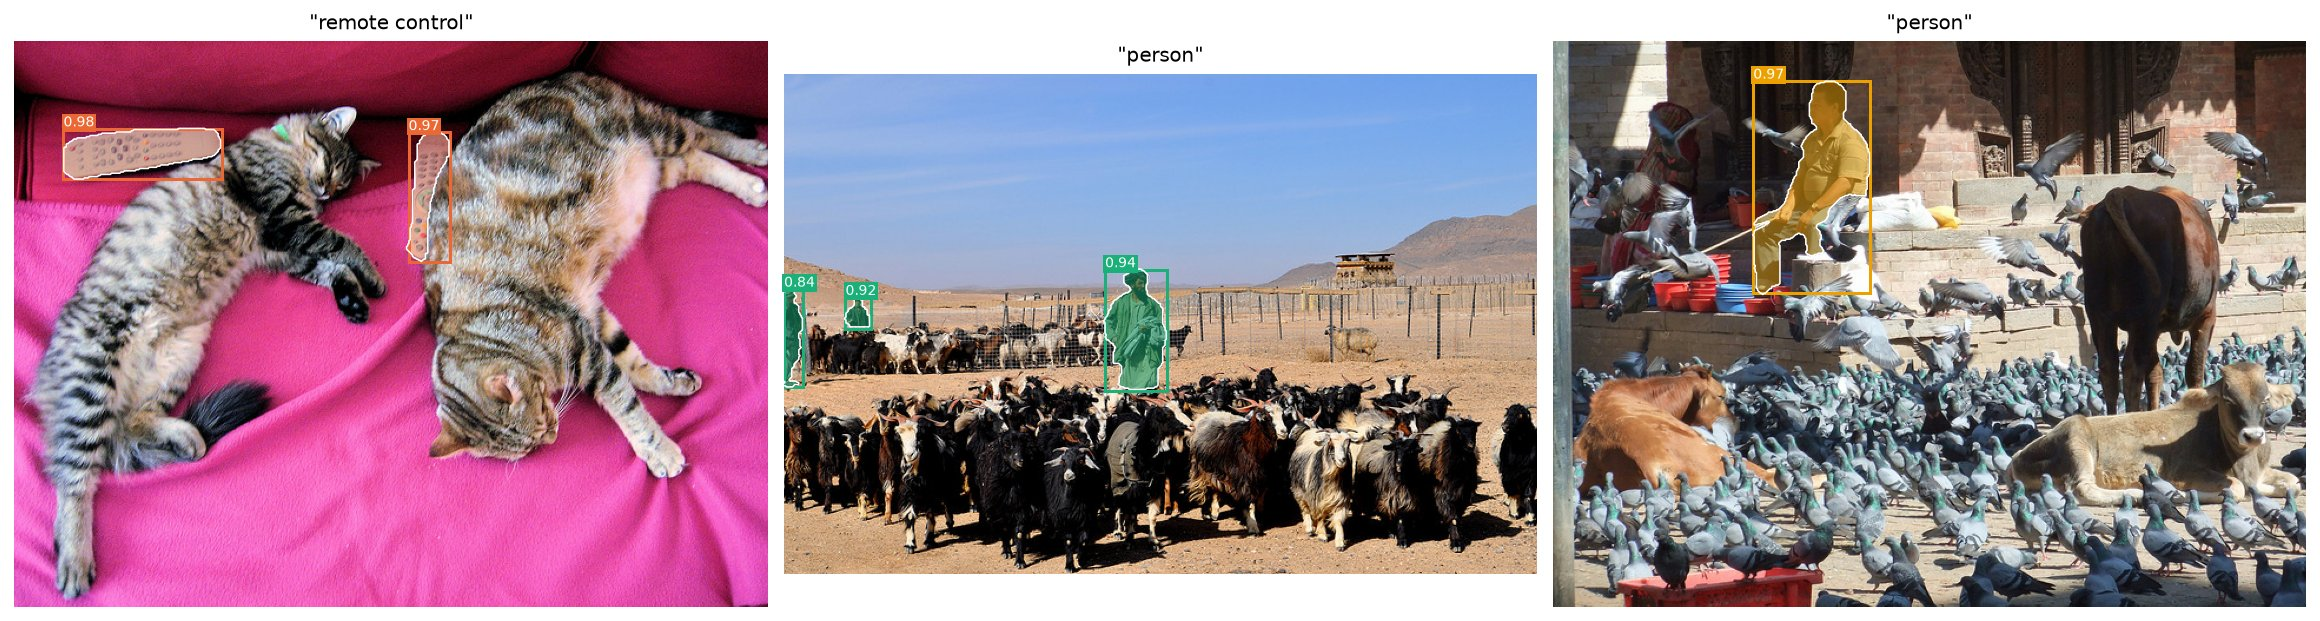

In [13]:
images, texts = [cats, goats, pigeons], ["remote control", "person", "person"]
inputs = processor(images=images, text=texts, return_tensors="pt").to(device)
with torch.no_grad():
    outputs = model(**inputs)
batch_results = processor.post_process_instance_segmentation(
    outputs, threshold=0.5, target_sizes=inputs["original_sizes"].tolist()
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), layout="constrained")
for ax, image, text, results, color in zip(axes, images, texts, batch_results, COLORS[1:]):
    show(ax, image, results["masks"].cpu(), results["boxes"].cpu(), results["scores"].cpu(), color=color, title=f'"{text}"')
plt.show()

## 4. Semantic segmentation

Besides the instance masks, SAM 3 outputs `semantic_seg`: one map for the whole concept ("is this pixel part of any
goat?"), without separating the instances.

semantic map: (425, 640) torch.int64


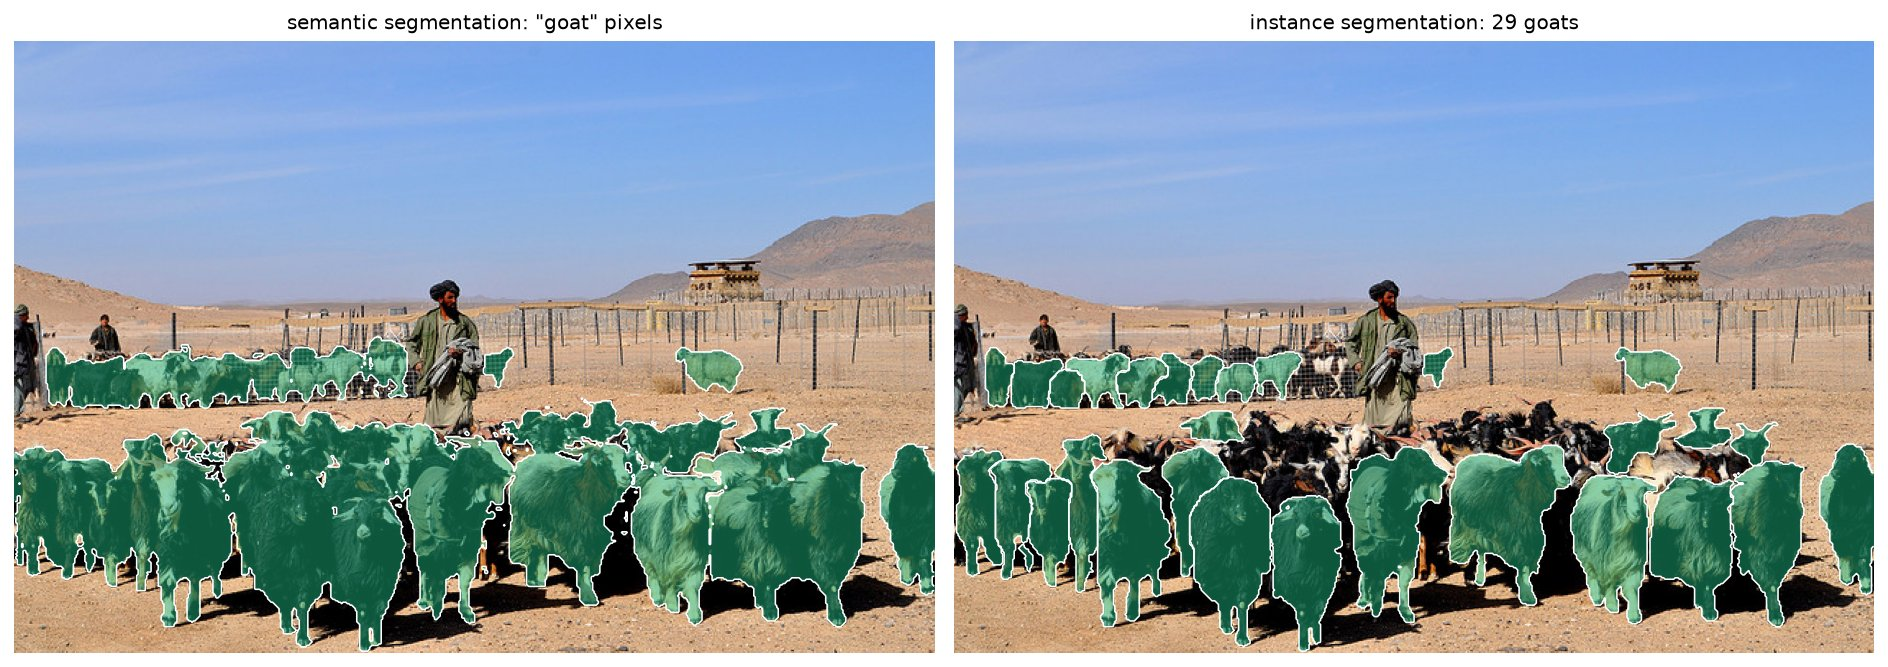

In [14]:
inputs = processor(images=goats, text="goat", return_tensors="pt").to(device)
with torch.no_grad():
    outputs = model(**inputs)
semantic = processor.post_process_semantic_segmentation(outputs, target_sizes=inputs["original_sizes"].tolist())[0].cpu()
print("semantic map:", tuple(semantic.shape), semantic.dtype)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
show(axes[0], goats, semantic[None], color=COLORS[2], title='semantic segmentation: "goat" pixels')
results = processor.post_process_instance_segmentation(outputs, threshold=0.5, target_sizes=inputs["original_sizes"].tolist())[0]
show(axes[1], goats, results["masks"].cpu(), color=COLORS[2], title=f"instance segmentation: {len(results['masks'])} goats")
plt.show()

## 5. Clicks: the SAM 2-style tracker

For segmenting **one specific object** by clicking on it, the same weights load as `Sam3TrackerModel` (the vision
encoder plus SAM 2's prompt encoder and mask decoder; no text). Points are in pixels with labels `1` = "this is the
object" and `0` = "this is not". The nesting is `[image][object][point]`.

A single click is ambiguous (the coat? the person? the two people walking side by side?), so by default the model
returns **3 candidate masks** with a predicted quality (IoU) score for each. The example is a busy street; we click on
one pedestrian on the left (the plots zoom into that part of the image).

458 M parameters


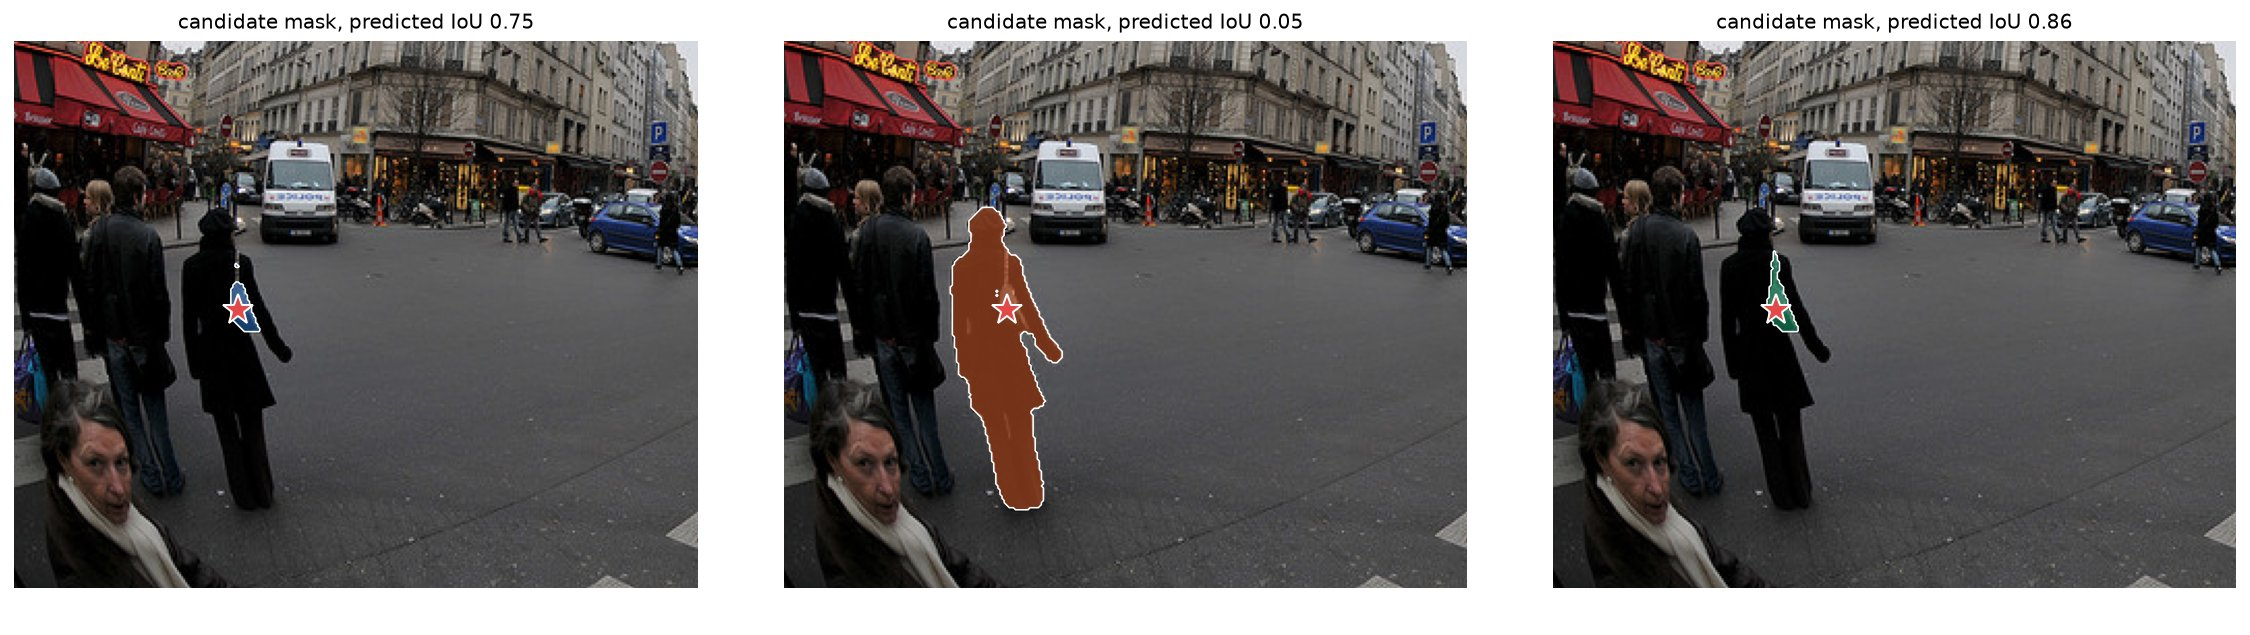

In [15]:
del model
torch.cuda.empty_cache()

from transformers import Sam3TrackerModel, Sam3TrackerProcessor

tracker = Sam3TrackerModel.from_pretrained(MODEL_DIR).to(device).eval()
tracker_processor = Sam3TrackerProcessor.from_pretrained(MODEL_DIR)
print(f"{sum(p.numel() for p in tracker.parameters()) / 1e6:.0f} M parameters")

street = load_coco(184324)
click = [108, 290]  # on the coat of a pedestrian, walking next to another one
ZOOM = dict(xlim=(0, 330), ylim=(440, 160))  # the left part of the street
inputs = tracker_processor(images=street, input_points=[[[click]]], input_labels=[[[1]]], return_tensors="pt").to(device)
with torch.no_grad():
    outputs = tracker(**inputs)
masks = tracker_processor.post_process_masks(outputs.pred_masks.cpu(), inputs["original_sizes"])[0][0]  # (3, H, W)
iou = outputs.iou_scores[0, 0].cpu()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), layout="constrained")
for ax, mask, score, color in zip(axes, masks, iou, COLORS):
    show(ax, street, mask[None], color=color, title=f"candidate mask, predicted IoU {score:.2f}")
    ax.plot(*click, marker="*", color="#e34948", markersize=16, markeredgecolor="white")
    ax.set(**ZOOM)
plt.show()

The candidate that is the whole person gets a *low* predicted IoU: the model isn't sure that's what we meant.
More clicks remove the ambiguity. With `multimask_output=False` the model returns one mask: here a second positive
click on the pedestrian's legs, and a negative click on the person next to them:

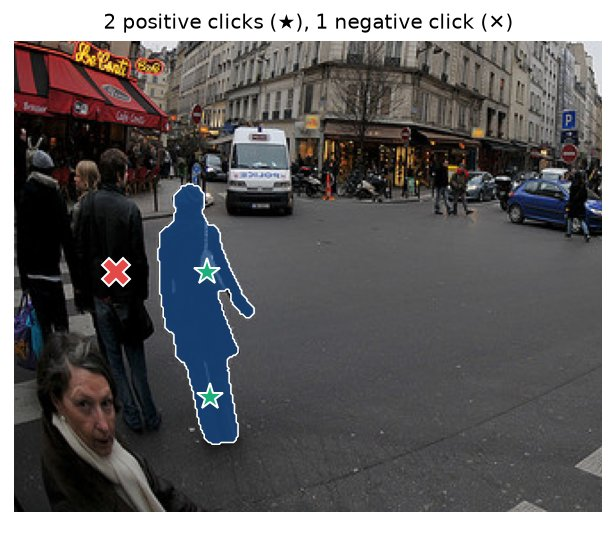

In [16]:
points, labels = [[108, 290], [110, 360], [57, 290]], [1, 1, 0]
inputs = tracker_processor(images=street, input_points=[[points]], input_labels=[[labels]], return_tensors="pt").to(device)
with torch.no_grad():
    outputs = tracker(**inputs, multimask_output=False)
mask = tracker_processor.post_process_masks(outputs.pred_masks.cpu(), inputs["original_sizes"])[0][0]

fig, ax = plt.subplots(figsize=(6, 4.5))
show(ax, street, mask, color=COLORS[0], title="2 positive clicks (★), 1 negative click (✕)")
for (x, y), label in zip(points, labels):
    ax.plot(x, y, marker="*" if label else "X", color="#1baf7a" if label else "#e34948", markersize=14,
            markeredgecolor="white")
ax.set(**ZOOM)
plt.show()

## 6. Videos: detect and track a concept

`Sam3VideoModel` combines both: it detects all instances of a text prompt and tracks each one through the video,
keeping its identity (`object_ids`) from frame to frame. A video is a sequence of frames, held in an
*inference session*; `propagate_in_video_iterator` yields the results frame by frame.

The example is a 20-second clip from [EPIC-KITCHENS-100](https://epic-kitchens.github.io/) (Damen et al. 2022):
videos recorded with head-mounted cameras in people's own kitchens, 1920 × 1080 at 50 frames per second. The course
bucket has 90 such clips (`s3://danylo-ucla/epic-kitchens/clips/`, CC BY-NC 4.0: non-commercial use only). We take
the first 10 seconds at 5 frames per second: 50 frames.

In [17]:
del tracker
torch.cuda.empty_cache()

import cv2
from transformers import Sam3VideoModel, Sam3VideoProcessor

CLIP = "P02_105_0060"  # washing up at a sink
clip_path = Path("sam3_data") / f"{CLIP}.mp4"
if not clip_path.exists():
    clip_path.parent.mkdir(exist_ok=True)
    s3fs.S3FileSystem().get(f"danylo-ucla/epic-kitchens/clips/{CLIP}.mp4", str(clip_path))

capture, frames = cv2.VideoCapture(str(clip_path)), []
fps = capture.get(cv2.CAP_PROP_FPS)
while len(frames) < 50:
    ok, frame = capture.read()
    if not ok:
        break
    if int(capture.get(cv2.CAP_PROP_POS_FRAMES) - 1) % 10 == 0:  # every 10th frame: 50 fps -> 5 fps
        frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
frames = np.stack(frames)
print("frames:", frames.shape, f"(5 of the clip's {fps:.0f} frames per second)")

video_model = Sam3VideoModel.from_pretrained(MODEL_DIR).to(device).eval()
video_processor = Sam3VideoProcessor.from_pretrained(MODEL_DIR)

frames: (50, 1080, 1920, 3) (5 of the clip's 50 frames per second)


In [18]:
session = video_processor.init_video_session(video=frames, inference_device=device, processing_device="cpu",
                                             video_storage_device="cpu", dtype=torch.float32)
session = video_processor.add_text_prompt(inference_session=session, text="glove")

start, tracked = time.time(), {}
with torch.no_grad():
    for frame_outputs in video_model.propagate_in_video_iterator(inference_session=session,
                                                                 max_frame_num_to_track=len(frames)):
        tracked[frame_outputs.frame_idx] = video_processor.postprocess_outputs(session, frame_outputs)
print(f"{len(tracked)} frames in {time.time() - start:.0f} s; first frame:",
      {name: tuple(value.shape) for name, value in tracked[0].items() if hasattr(value, "shape")})

50 frames in 26 s; first frame: {'object_ids': (2,), 'scores': (2,), 'boxes': (2, 4), 'masks': (2, 1080, 1920)}


Each tracked glove keeps one color (by `object_id`) across the frames, 2 seconds apart:

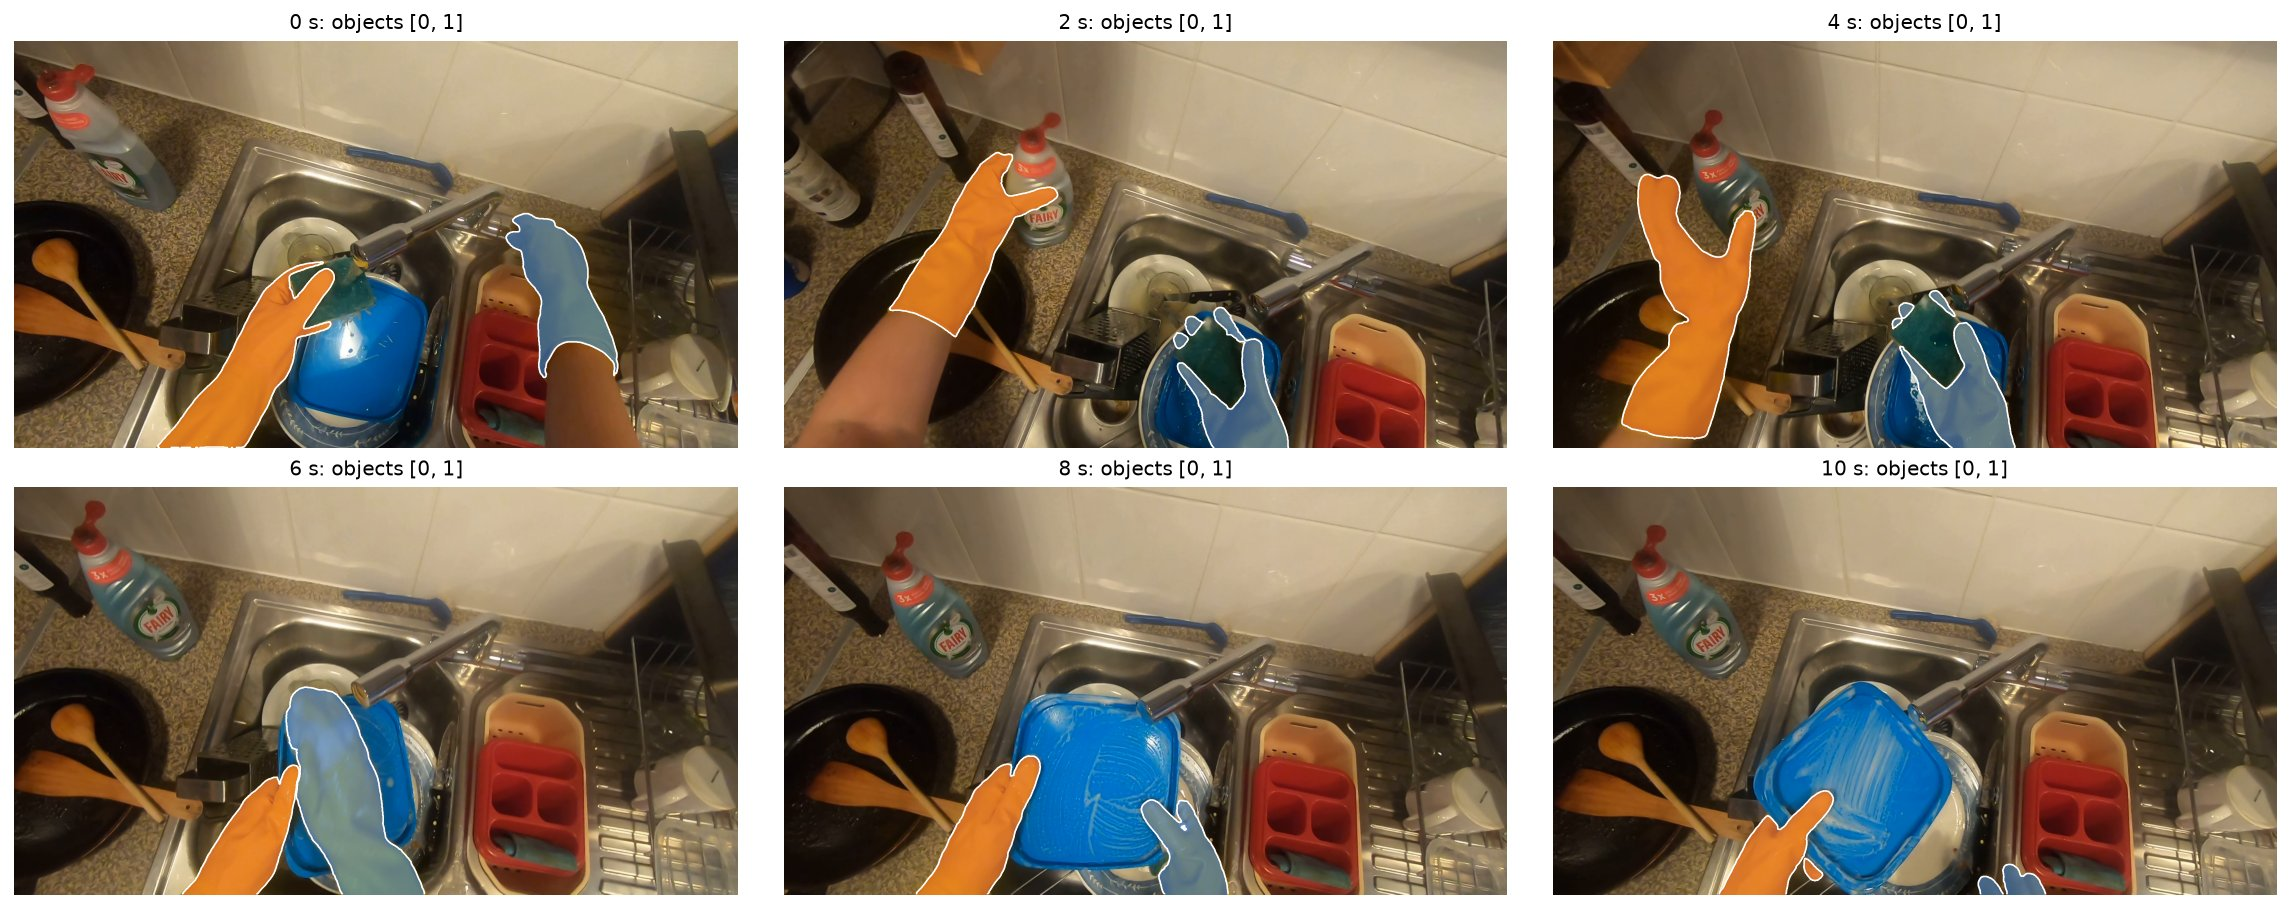

In [19]:
shown = [0, 10, 20, 30, 40, 49]
fig, axes = plt.subplots(2, 3, figsize=(16, 6.2), layout="constrained")
for ax, frame_idx in zip(axes.flat, shown):
    result = tracked[frame_idx]
    ax.imshow(frames[frame_idx])
    for object_id, mask in zip(result["object_ids"].tolist(), result["masks"].cpu().numpy()):
        overlay = np.zeros((*mask.shape, 4))
        overlay[mask > 0] = (*plt.matplotlib.colors.to_rgb(COLORS[object_id % len(COLORS)]), 0.6)
        ax.imshow(overlay)
        ax.contour(mask, levels=[0.5], colors="white", linewidths=0.8)
    ax.set_title(f"{frame_idx / 5:.0f} s: objects {result['object_ids'].tolist()}", fontsize=10)
    ax.axis("off")
plt.show()

## Summary

The same `facebook/sam3` weights load as four models, depending on the task:

| class | input | prompt | output |
|---|---|---|---|
| `Sam3Model` | image | text and/or example boxes | all instances: masks, boxes, scores; semantic map |
| `Sam3TrackerModel` | image | points, boxes (one object each) | one mask per object (or 3 candidates with IoU scores) |
| `Sam3VideoModel` | video | text | all instances, tracked with object ids |
| `Sam3TrackerVideoModel` | video | points, boxes on a frame | the clicked objects, tracked (SAM 2-style) |

Things to keep in mind:
- prompts are short **noun phrases** ("red car", "person wearing a hat"), not sentences or questions;
- `threshold` trades missed objects for false detections; the presence score handles absent concepts;
- for several prompts on one image, compute `vision_embeds` once;
- boxes and points are in **pixels** of the original image, `[x0, y0, x1, y1]` and `[x, y]`.